# 03. Exploratory Data Analysis & Feature Engineering
**Course Code:** U23AD491 Data Science Project | **Unit IV: Data Preprocessing & EDA**

### Learning Objectives:
1. Missing value imputation: Comparing Mean/Median vs Time-series Forward-Fill & Linear Interpolation.
2. Outlier diagnostics with IQR and Z-scores.
3. Temporal feature engineering: Diurnal hour, day-of-week, rolling windows (15m, 60m), and lag differencing.
4. Dimensionality reduction via Principal Component Analysis (PCA).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

feat_path = Path('../data/processed/featured_metrics.csv')
df_feat = pd.read_csv(feat_path)
print(f'Engineered Feature Matrix Shape: {df_feat.shape}')
print(df_feat[['response_time_ms', 'latency_roll_mean_15m', 'latency_diff_1', 'hourly_z_deviation', 'pca_1', 'pca_2']].head())

Engineered Feature Matrix Shape: (51840, 51)
   response_time_ms  latency_roll_mean_15m  latency_diff_1  \
0             51.87              51.870000            0.00   
1             41.89              46.880000           -9.98   
2             34.50              42.753333           -7.39   
3             44.49              40.293333            9.99   
4             42.35              40.446667           -2.14   

   hourly_z_deviation     pca_1     pca_2  
0            0.401363 -1.806644 -1.259348  
1           -0.404044 -2.295864 -2.091368  
2           -1.000433 -2.270081 -1.808529  
3           -0.194219 -2.511297 -2.076753  
4           -0.366921 -2.330824 -1.785714  


### PCA 2D Dimensionality Reduction
Visualizing high-dimensional telemetry projection colored by ground-truth anomaly state.

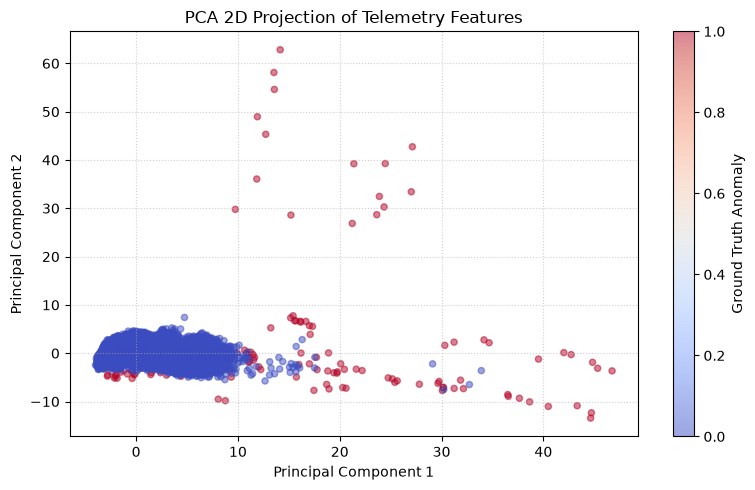

In [2]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df_feat['pca_1'], df_feat['pca_2'], c=df_feat['is_anomaly'], cmap='coolwarm', alpha=0.5, s=20)
plt.colorbar(scatter, label='Ground Truth Anomaly')
plt.title('PCA 2D Projection of Telemetry Features')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()